# Detecção de Imagens Sintéticas após Transformações

**Objetivo:** medir a robustez de features clássicas (FFT, HOG, LBP) + SVM no CIFAKE quando as imagens sofrem compressão, crop, resize, blur etc.

**Fluxo:** carregar dados → extrair features (só originais) → treinar SVM → aplicar transformações → medir queda de acurácia por feature.

> Desenvolvedores: Igor de Matos da Rosa e Nathália Geraldino Ribas

## 1. Setup e caminhos
Preparar o ambiente e apontar para o CIFAKE.

In [22]:
# Este bloco visa importar bibliotecas necessárias:
# - random (aleatoriedade)
# - numpy, pandas (dados e tabelas)
# - PIL / opencv (ler e transformar imagens)
# - skimage (HOG, LBP)
# - sklearn (LinearSVC — SVM linear rápido, métricas, StandardScaler)
# - matplotlib / seaborn (gráficos)
# - pathlib / os (caminhos)
# - joblib (salvar modelos .pkl)   
import os
import random
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import GridSearchCV
# LinearSVC = rápido (padrão). SVC(RBF) = opcional na fusão, mais preciso e mais lento.
from tqdm import tqdm

# Evita acumular dezenas de figuras abertas em execução longa (Run All / noite)
import atexit

def _fechar_figuras():
    plt.close("all")

atexit.register(_fechar_figuras)

<function __main__._fechar_figuras()>

In [23]:
# Define caminhos do projeto:
# - pasta raiz do repositório
# - caminho do CIFAKE ../Base/archive (bifurca em teste e treino)
# - pastas de saída: models/ e results/
# Fixar seed aleatória para reprodutibilidade

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define pastas
ROOT_DIR = Path.cwd()

# Tenta localizar a pasta archive
possible_dataset_paths = [
    ROOT_DIR / "Base" / "archive",
    ROOT_DIR.parent / "Base" / "archive",
    ROOT_DIR / "archive",
]

DATASET_DIR = None
for path in possible_dataset_paths:
    if path.exists():
        DATASET_DIR = path
        break

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Não foi possível encontrar a pasta 'Base/archive' contendo o dataset CIFAKE."
    )

# Bifurcação em treino e teste
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Pastas de saída: models/ e results/
MODELS_DIR = ROOT_DIR / "models"
RESULTS_DIR = ROOT_DIR / "results"

# Criar pastas de saída caso não existam
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Confirmação dos caminhos encontrados
print(f"Dataset encontrado em: {DATASET_DIR}")
print(f"Treino existe? {TRAIN_DIR.exists()}")
print(f"Teste existe? {TEST_DIR.exists()}")

Dataset encontrado em: /home/igor/Documentos/UFSC/Trabalhos/VisaoComp/DeteccaoImagensSinteticas/Base/archive
Treino existe? True
Teste existe? True


## 2. Carregar o CIFAKE
Dataset balanceado REAL/FAKE, já separado em treino e teste.

In [24]:
# Função para listar imagens das pastas REAL/ e FAKE/
# Retornar: lista de caminhos + rótulos (0=FAKE, 1=REAL)
# Aplicar para train/ e test/
# Conferir quantas imagens há em cada classe

from pathlib import Path
from collections import Counter

def listar_imagens(pasta_base):
    caminhos = []
    rotulos = []

    classes = {
        "FAKE": 0,
        "REAL": 1
    }

    extensoes = {".jpg", ".jpeg", ".png"}

    for classe, rotulo in classes.items():
        pasta_classe = Path(pasta_base) / classe

        for imagem in pasta_classe.iterdir():
            if imagem.suffix.lower() in extensoes:
                caminhos.append(str(imagem))
                rotulos.append(rotulo)

    return caminhos, rotulos

def criar_subconjunto(caminhos, rotulos, quantidade_por_classe=2000, seed=SEED):
    """Amostra aleatória balanceada por classe (para acelerar prototipagem/treino)."""
    rng = np.random.default_rng(seed)
    fake_idx = [i for i, r in enumerate(rotulos) if r == 0]
    real_idx = [i for i, r in enumerate(rotulos) if r == 1]

    n_fake = min(quantidade_por_classe, len(fake_idx))
    n_real = min(quantidade_por_classe, len(real_idx))

    escolhidos = list(rng.choice(fake_idx, size=n_fake, replace=False))
    escolhidos += list(rng.choice(real_idx, size=n_real, replace=False))
    rng.shuffle(escolhidos)

    caminhos_sub = [caminhos[i] for i in escolhidos]
    rotulos_sub = [rotulos[i] for i in escolhidos]
    return caminhos_sub, rotulos_sub

# Usa os caminhos definidos no setup (TRAIN_DIR / TEST_DIR)
train_caminhos, train_rotulos = listar_imagens(TRAIN_DIR)
test_caminhos, test_rotulos = listar_imagens(TEST_DIR)

print("Train (completo):", Counter(train_rotulos))
print("Test (completo):", Counter(test_rotulos))

Train (completo): Counter({0: 50000, 1: 50000})
Test (completo): Counter({0: 10000, 1: 10000})


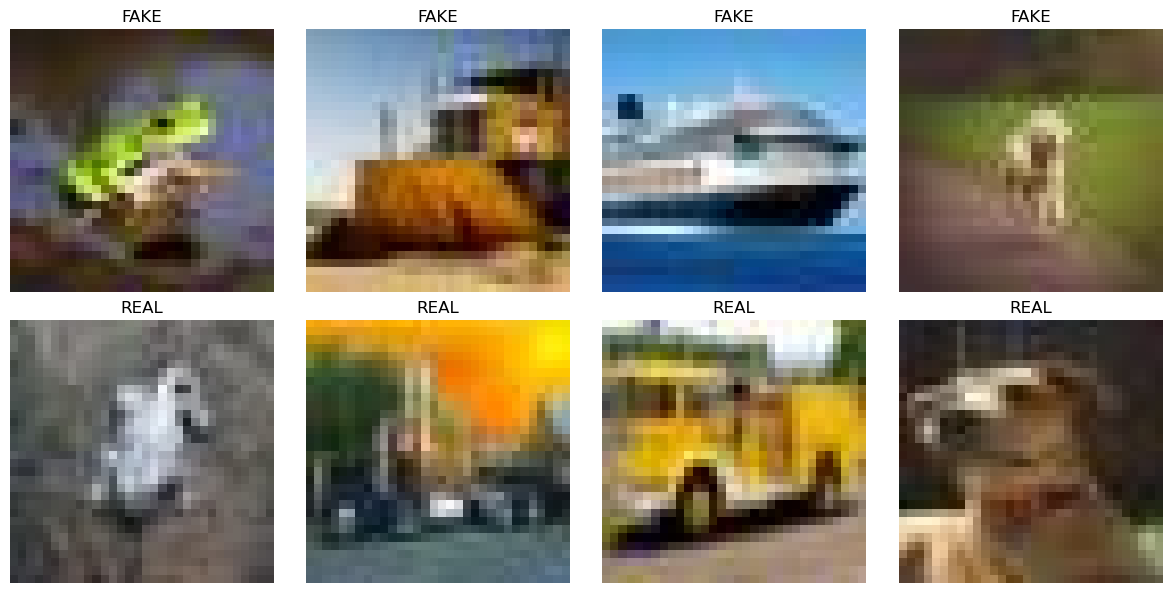

In [25]:
# Função para carregar uma imagem:
# - abrir arquivo
# - garantir tamanho consistente
# - converter para o formato usado nas features
# Mostrar exemplos (REAL e FAKE)

def carregar_imagem(caminho):
    imagem = cv2.imread(caminho)

    if imagem is None:
        raise ValueError(f"Não foi possível carregar a imagem: {caminho}")

    # Mantemos 32x32, tamanho original do CIFAKE
    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    return imagem

import matplotlib.pyplot as plt

def mostrar_exemplos(caminhos, rotulos, quantidade=4):
    fake = []
    real = []

    for caminho, rotulo in zip(caminhos, rotulos):

        if rotulo == 0 and len(fake) < quantidade:
            fake.append(caminho)

        elif rotulo == 1 and len(real) < quantidade:
            real.append(caminho)

        if len(fake) == quantidade and len(real) == quantidade:
            break

    exemplos = fake + real

    plt.figure(figsize=(12, 6))

    for i, caminho in enumerate(exemplos):
        imagem = carregar_imagem(caminho)

        plt.subplot(2, quantidade, i + 1)
        plt.imshow(imagem)
        plt.axis("off")

        if i < quantidade:
            plt.title("FAKE")
        else:
            plt.title("REAL")

    plt.tight_layout()
    plt.show()

mostrar_exemplos(train_caminhos, train_rotulos)

## 3. Extratores de features
Três famílias alinhadas à disciplina: **frequência (FFT)**, **espaço (HOG)**, **textura (LBP)**.

In [26]:
# Implementa extrator FFT:
# - converte imagem para cinza
# - calcula FFT 2D e espectro de magnitude
# - shift para centralizar baixas frequências
# - transforma em vetor 1D
# - normaliza o vetor
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_fft(imagem, num_bins=64):
    """Extrai o perfil azimutal (média radial) do espectro de magnitude da FFT 2D.

    - Converte para escala de cinza
    - Aplica FFT 2D com shift para centralizar frequências
    - Calcula o espectro de magnitude logarítmico
    - Reduz a um vetor 1D balanceado via média radial (histograma de frequências)
    - Normaliza o vetor (Escala [0, 1])
    """
    # 1. Converter para escala de cinza
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # 2. Calcular FFT 2D
    fft_2d = np.fft.fft2(imagem_cinza)

    # 3. Shift para centralizar baixas frequências no meio do espectro
    fft_shifted = np.fft.fftshift(fft_2d)

    # Espectro de magnitude (com escala logarítmica para suavizar picos)
    magnitude_spectrum = np.log(np.abs(fft_shifted) + 1e-8)

    # 4. Transformar em vetor 1D via Média Radial (Perfil Azimutal de Frequência)
    h, w = magnitude_spectrum.shape
    centro_y, centro_x = h // 2, w // 2

    # Matriz de distâncias ao centro
    y, x = np.ogrid[:h, :w]
    raios = np.sqrt((x - centro_x) ** 2 + (y - centro_y) ** 2)

    # Binning radial para criar o vetor 1D
    raio_max = np.sqrt(centro_x**2 + centro_y**2)
    bins = np.linspace(0, raio_max, num_bins + 1)

    vetor_fft = np.zeros(num_bins)
    for i in range(num_bins):
        mascara = (raios >= bins[i]) & (raios < bins[i + 1])
        if np.any(mascara):
            vetor_fft[i] = np.mean(magnitude_spectrum[mascara])

    # 5. Normalizar o vetor 1D (Min-Max para [0, 1])
    min_val = np.min(vetor_fft)
    max_val = np.max(vetor_fft)
    if max_val - min_val > 1e-8:
        vetor_fft = (vetor_fft - min_val) / (max_val - min_val)

    return vetor_fft


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_fft = extrair_features_fft(img_teste)

print(f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}")
print(f"Shape do vetor de features FFT: {vetor_fft.shape}")
print("Primeiros valores do vetor normalizado:", np.round(vetor_fft[:5], 4))

Classe da imagem de teste: FAKE
Shape do vetor de features FFT: (64,)
Primeiros valores do vetor normalizado: [1.     0.     0.8408 0.     0.738 ]


In [27]:
# Implementa extrator HOG:
# - usa skimage.feature.hog
# - define parâmetros razoáveis para 32x32 (pixels_per_cell, cells_per_block, orientations)
# - retorna o vetor de features
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_hog(
    imagem,
    orientations=8,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
):
    """Extrai o vetor de características HOG de uma imagem 32x32.

    Parâmetros adequados para 32x32:
    - pixels_per_cell: (8, 8) divide a imagem em uma grade de 4x4 células.
    - cells_per_block: (2, 2) normaliza a iluminação em blocos 2x2 células.
    - orientations: 8 direções de gradientes (suficiente para 32x32).
    """
    
    # Converter para cinza se for imagem colorida
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # Extração HOG
    vetor_hog = hog(
        imagem_cinza,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        visualize=False,
    )

    return vetor_hog


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_hog = extrair_features_hog(img_teste)

print(
    f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}"
)
print(f"Shape do vetor de features HOG: {vetor_hog.shape}")
print("Primeiros valores do vetor HOG:", np.round(vetor_hog[:5], 4))

Classe da imagem de teste: FAKE
Shape do vetor de features HOG: (288,)
Primeiros valores do vetor HOG: [0.0165 0.0246 0.0718 0.0683 0.179 ]


In [28]:
# Implementa extrator LBP:
# - usa skimage.feature.local_binary_pattern
# - escolhe P (vizinhos) e R (raio)
# - monta histograma do LBP como vetor de features
# - normaliza o histograma
# Testa em 1 imagem e imprimir o shape do vetor

def extrair_features_lbp(imagem, P=8, R=1, method="uniform"):
    """Extrai o histograma normalizado do LBP de uma imagem 32x32.

    Parâmetros:
    - P: Número de pontos vizinhos circularmente simétricos (padrão: 8).
    - R: Raio do círculo para vizinhança (padrão: 1).
    - method: 'uniform' produz padrões invariantes a rotação e reduz
      o tamanho do vetor para P + 2 bins (10 bins para P=8).
    """
    # 1. Converter para escala de cinza se necessário
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()

    # 2. Calcular o mapa LBP
    lbp_mapa = local_binary_pattern(imagem_cinza, P=P, R=R, method=method)

    # 3. Montar o histograma do LBP como vetor de características
    # Para o método 'uniform', existem P + 2 bins
    n_bins = P + 2 if method == "uniform" else int(lbp_mapa.max() + 1)
    hist, _ = np.histogram(
        lbp_mapa.ravel(), bins=n_bins, range=(0, n_bins)
    )

    # 4. Normalizar o histograma (soma igual a 1)
    hist = hist.astype("float")
    soma = hist.sum()
    if soma > 0:
        hist /= soma

    return hist


# --- Teste em 1 imagem ---
img_teste = carregar_imagem(train_caminhos[0])
vetor_lbp = extrair_features_lbp(img_teste)

print(
    f"Classe da imagem de teste: {'REAL' if train_rotulos[0] == 1 else 'FAKE'}"
)
print(f"Shape do vetor de features LBP: {vetor_lbp.shape}")
print("Valores do histograma LBP normalizado:", np.round(vetor_lbp, 4))

Classe da imagem de teste: FAKE
Shape do vetor de features LBP: (10,)
Valores do histograma LBP normalizado: [0.0566 0.0791 0.0479 0.1289 0.2744 0.126  0.0635 0.0596 0.0547 0.1094]


In [29]:
# Função genérica: dado uma lista de caminhos + nome da feature ("fft"|"hog"|"lbp"),
# extrai features de todas as imagens e empilhar em matriz X
# Retornar X (n_amostras x n_features) e y (rótulos)
# Mostrar progresso (tqdm)
# Salva em ./local/*.npz e RECARREGA do cache se o arquivo já existir (forcar_recalculo=True para refazer)

def extrair_e_salvar_features(
    caminhos,
    rotulos,
    tipo_feature,
    pasta_saida="./local",
    nome_arquivo=None,
    forcar_recalculo=False,
):
    """Extrai features ('fft', 'hog' ou 'lbp'), salva em .npz e reutiliza cache."""
    extratores = {
        "fft": extrair_features_fft,
        "hog": extrair_features_hog,
        "lbp": extrair_features_lbp,
    }

    if tipo_feature not in extratores:
        raise ValueError(
            f"Tipo de feature '{tipo_feature}' inválido. Escolha entre: {list(extratores.keys())}"
        )

    diretorio_saida = Path(pasta_saida)
    diretorio_saida.mkdir(parents=True, exist_ok=True)

    if nome_arquivo is None:
        nome_arquivo = f"features_{tipo_feature}.npz"

    caminho_salvar = diretorio_saida / nome_arquivo

    # Reutiliza cache se o arquivo já existe (evita recalcular)
    if caminho_salvar.exists() and not forcar_recalculo:
        dados = np.load(caminho_salvar)
        X, y = dados["X"], dados["y"]
        print(f"Cache carregado: {caminho_salvar} | X={X.shape}, y={y.shape}")
        return X, y

    funcao_extratora = extratores[tipo_feature]
    features_list = []
    print(f"Extraindo features [{tipo_feature.upper()}]...")

    for caminho in tqdm(caminhos, desc=f"Processando ({tipo_feature})"):
        img = carregar_imagem(caminho)
        vetor = funcao_extratora(img)
        features_list.append(vetor)

    X = np.array(features_list)
    y = np.array(rotulos)

    np.savez_compressed(caminho_salvar, X=X, y=y)
    print(f"Matrizes salvas com sucesso em: {caminho_salvar}")

    return X, y

# --- Exemplo de teste com o subconjunto de treino ---
# X_train_hog, y_train_hog = extrair_e_salvar_features(train_caminhos, train_rotulos, tipo_feature="hog")
# print("Shape da matriz X:", X_train_hog.shape)
# print("Shape do vetor y:", y_train_hog.shape)

## 4. Features do conjunto ORIGINAL (treino e teste)
**Importante:** o SVM treina só em imagens **sem** transformação (baseline).

In [30]:
# Prepara features ORIGINAIS (baseline)
# Decisão: subconjunto balanceado para acelerar (troque MODO abaixo)
# Decisão: StandardScaler com fit só no treino — evita vazamento de informação do teste
# Decisão: cache .npz com tamanho no nome (não mistura subset com dataset completo)

# Escala do experimento — só mude MODO para reexecutar mais rápido/mais completo
#   rapido   → prototipagem
#   medio    → padrão do projeto
#   completo → dataset inteiro (mais lento na extração)
# Escala do experimento (mais dados → em geral melhor acurácia)
#   rapido   → prototipagem (~0.65–0.76 por feature isolada)
#   medio    → bom equilíbrio
#   forte    → recomendado para relatório (fusão costuma passar de ~0.85)
#   completo → dataset inteiro (extração bem mais lenta)
MODO = "forte"
CONFIG_SUBSET = {
    "rapido": {"treino": 1000, "teste": 300},
    "medio": {"treino": 2000, "teste": 500},
    "forte": {"treino": 5000, "teste": 1000},
    "completo": {"treino": None, "teste": None},
}
if MODO not in CONFIG_SUBSET:
    raise ValueError(f"MODO inválido: {MODO}. Use {list(CONFIG_SUBSET)}")

N_TREINO_POR_CLASSE = CONFIG_SUBSET[MODO]["treino"]
N_TESTE_POR_CLASSE = CONFIG_SUBSET[MODO]["teste"]
print(f"MODO={MODO} | treino/classe={N_TREINO_POR_CLASSE} | teste/classe={N_TESTE_POR_CLASSE}")

if N_TREINO_POR_CLASSE is None:
    train_caminhos_usados, train_rotulos_usados = train_caminhos, train_rotulos
else:
    train_caminhos_usados, train_rotulos_usados = criar_subconjunto(
        train_caminhos, train_rotulos, quantidade_por_classe=N_TREINO_POR_CLASSE
    )

if N_TESTE_POR_CLASSE is None:
    test_caminhos_usados, test_rotulos_usados = test_caminhos, test_rotulos
else:
    test_caminhos_usados, test_rotulos_usados = criar_subconjunto(
        test_caminhos, test_rotulos, quantidade_por_classe=N_TESTE_POR_CLASSE
    )

# Sufixo do cache: tamanho real do conjunto usado
TAG_TREINO = len(train_caminhos_usados)
TAG_TESTE = len(test_caminhos_usados)

print("Treino (subconjunto):", len(train_caminhos_usados), Counter(train_rotulos_usados))
print("Teste (subconjunto):", len(test_caminhos_usados), Counter(test_rotulos_usados))

tipos_features = ["fft", "hog", "lbp"]

features = {}
scalers = {}

for tipo in tipos_features:
    print(f"\nProcessando {tipo.upper()}")
    # Nome do cache inclui o tamanho do subset (evita misturar com .npz do dataset completo)
    X_train_original, y_train = extrair_e_salvar_features(
        caminhos=train_caminhos_usados,
        rotulos=train_rotulos_usados,
        tipo_feature=tipo,
        pasta_saida="./local",
        nome_arquivo=f"features_{tipo}_train_n{TAG_TREINO}.npz",
    )

    X_test_original, y_test = extrair_e_salvar_features(
        caminhos=test_caminhos_usados,
        rotulos=test_rotulos_usados,
        tipo_feature=tipo,
        pasta_saida="./local",
        nome_arquivo=f"features_{tipo}_test_n{TAG_TESTE}.npz",
    )

    # Verifica se matrizes e rótulos são compatíveis e contêm valores válidos.
    assert X_train_original.shape[0] == y_train.shape[0]
    assert X_test_original.shape[0] == y_test.shape[0]
    assert X_train_original.shape[1] == X_test_original.shape[1]
    assert np.isfinite(X_train_original).all()
    assert np.isfinite(X_test_original).all()

    # Ajusta o scaler somente no treino e usa as mesmas estatísticas no teste.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_original)
    X_test_scaled = scaler.transform(X_test_original)

    # Organiza os dados para o treinamento dos SVMs na próxima seção.
    features[tipo] = {
        "X_train": X_train_scaled,
        "y_train": y_train,
        "X_test": X_test_scaled,
        "y_test": y_test,
    }
    scalers[tipo] = scaler

    print("Treino:", X_train_scaled.shape, "| Teste:", X_test_scaled.shape)
    print("Classes no treino:", np.unique(y_train, return_counts=True))
    print("Classes no teste:", np.unique(y_test, return_counts=True))

MODO=rapido | treino/classe=1000 | teste/classe=300


Treino (subconjunto): 2000 Counter({0: 1000, 1: 1000})
Teste (subconjunto): 600 Counter({0: 300, 1: 300})

Processando FFT
Cache carregado: local/features_fft_train_n2000.npz | X=(2000, 64), y=(2000,)
Cache carregado: local/features_fft_test_n600.npz | X=(600, 64), y=(600,)
Treino: (2000, 64) | Teste: (600, 64)
Classes no treino: (array([0, 1]), array([1000, 1000]))
Classes no teste: (array([0, 1]), array([300, 300]))

Processando HOG
Cache carregado: local/features_hog_train_n2000.npz | X=(2000, 288), y=(2000,)
Cache carregado: local/features_hog_test_n600.npz | X=(600, 288), y=(600,)
Treino: (2000, 288) | Teste: (600, 288)
Classes no treino: (array([0, 1]), array([1000, 1000]))
Classes no teste: (array([0, 1]), array([300, 300]))

Processando LBP
Cache carregado: local/features_lbp_train_n2000.npz | X=(2000, 10), y=(2000,)
Cache carregado: local/features_lbp_test_n600.npz | X=(600, 10), y=(600,)
Treino: (2000, 10) | Teste: (600, 10)
Classes no treino: (array([0, 1]), array([1000, 100

In [31]:
# Resumo + montagem da FUSÃO (FFT + HOG + LBP concatenados)
# Decisão: concatenar features já escaladas por família (ordem fixa: fft, hog, lbp)
print("Features preparadas:", list(features.keys()))
print("Scalers preparados:", list(scalers.keys()))

for tipo in tipos_features:
    dados = features[tipo]
    print(
        f"{tipo.upper()}: "
        f"X_train={dados['X_train'].shape}, "
        f"X_test={dados['X_test'].shape}, "
        f"média_treino={dados['X_train'].mean():.3e}"
    )

features["fusion"] = {
    "X_train": np.hstack([features[t]["X_train"] for t in tipos_features]),
    "y_train": features[tipos_features[0]]["y_train"],
    "X_test": np.hstack([features[t]["X_test"] for t in tipos_features]),
    "y_test": features[tipos_features[0]]["y_test"],
}
print(
    f"FUSION: X_train={features['fusion']['X_train'].shape}, "
    f"X_test={features['fusion']['X_test'].shape}"
)

Features preparadas: ['fft', 'hog', 'lbp']
Scalers preparados: ['fft', 'hog', 'lbp']
FFT: X_train=(2000, 64), X_test=(600, 64), média_treino=3.695e-16
HOG: X_train=(2000, 288), X_test=(600, 288), média_treino=8.139e-17
LBP: X_train=(2000, 10), X_test=(600, 10), média_treino=7.674e-17


## 5. Treinar classificador (baseline)

Treinamos nos originais:
1. **1 SVM por feature** (FFT, HOG, LBP) — para comparar domínios
2. **1 SVM na fusão** (FFT+HOG+LBP concatenados) — para subir a acurácia

**Decisões:**
- `LinearSVC` como padrão (SVM linear, rápido, alinhado à disciplina).
- Fusão de features (como na literatura handcrafted) costuma subir bastante o baseline.
- Opcional: `SVC(RBF)` só na fusão (`USAR_RBF_NA_FUSAO=True`) se quiser mais pontuação e puder esperar.

In [32]:
# Treina baselines: 1 modelo por feature + 1 modelo na FUSÃO
# Decisão: LinearSVC (SVM linear) — rápido e alinhado à disciplina
# Decisão: na fusão, busca C em grade pequena (melhora acurácia com pouco custo)
# Decisão: RBF opcional só na fusão (mais preciso, mais lento)

USAR_RBF_NA_FUSAO = True  # True = tenta SVC(RBF) além do LinearSVC na fusão
AJUSTAR_C = True          # True = GridSearchCV no C do LinearSVC (fusão)

def criar_linear_svc(C=1.0):
    return LinearSVC(C=C, dual=False, max_iter=8000, random_state=SEED)


def treinar_e_avaliar(nome, X_train, y_train, X_test, y_test, modelo):
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    return modelo, acc, y_pred


baseline_results = {}
tabela_resumo = []
tipos_modelos = list(tipos_features) + ["fusion"]

# 1) Modelos por feature isolada
for tipo in tipos_features:
    print(f"Treinando LinearSVC [{tipo.upper()}]...")
    modelo, acc, y_pred = treinar_e_avaliar(
        tipo,
        features[tipo]["X_train"],
        features[tipo]["y_train"],
        features[tipo]["X_test"],
        features[tipo]["y_test"],
        criar_linear_svc(C=1.0),
    )
    baseline_results[tipo] = {"modelo": modelo, "acuracia": acc, "y_pred": y_pred}
    tabela_resumo.append(
        {
            "feature": tipo.upper(),
            "modelo": "LinearSVC",
            "n_treino": len(features[tipo]["y_train"]),
            "acurácia": f"{acc:.4f}",
        }
    )
    print(f"  → acc={acc:.4f}")

# 2) Fusão FFT+HOG+LBP
print("\nTreinando fusão FFT+HOG+LBP...")
Xtr_f = features["fusion"]["X_train"]
ytr_f = features["fusion"]["y_train"]
Xte_f = features["fusion"]["X_test"]
yte_f = features["fusion"]["y_test"]

if AJUSTAR_C:
    gs = GridSearchCV(
        criar_linear_svc(),
        param_grid={"C": [0.01, 0.1, 1.0, 10.0, 50.0]},
        cv=3,
        n_jobs=-1,
        scoring="accuracy",
    )
    gs.fit(Xtr_f, ytr_f)
    modelo_fusion = gs.best_estimator_
    print(f"  Melhor C (LinearSVC fusão): {gs.best_params_['C']}")
else:
    modelo_fusion = criar_linear_svc(C=1.0)

modelo_fusion, acc_fusion, y_pred_f = treinar_e_avaliar(
    "fusion", Xtr_f, ytr_f, Xte_f, yte_f, modelo_fusion
)
baseline_results["fusion"] = {
    "modelo": modelo_fusion,
    "acuracia": acc_fusion,
    "y_pred": y_pred_f,
}
tabela_resumo.append(
    {
        "feature": "FUSION",
        "modelo": "LinearSVC",
        "n_treino": len(ytr_f),
        "acurácia": f"{acc_fusion:.4f}",
    }
)
print(f"  → FUSION LinearSVC acc={acc_fusion:.4f}")

# 3) Opcional: RBF na fusão (costuma ganhar alguns pontos)
if USAR_RBF_NA_FUSAO:
    print("\nTreinando FUSION com SVC(RBF) — pode demorar mais...")
    modelo_rbf = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=SEED)
    modelo_rbf, acc_rbf, y_pred_rbf = treinar_e_avaliar(
        "fusion_rbf", Xtr_f, ytr_f, Xte_f, yte_f, modelo_rbf
    )
    # Mantém o melhor entre LinearSVC e RBF como modelo oficial da fusão
    if acc_rbf >= acc_fusion:
        baseline_results["fusion"] = {
            "modelo": modelo_rbf,
            "acuracia": acc_rbf,
            "y_pred": y_pred_rbf,
        }
        print(f"  → FUSION RBF acc={acc_rbf:.4f} (melhor; será o usado)")
        tabela_resumo.append(
            {
                "feature": "FUSION",
                "modelo": "SVC-RBF",
                "n_treino": len(ytr_f),
                "acurácia": f"{acc_rbf:.4f}",
            }
        )
    else:
        print(
            f"  → FUSION RBF acc={acc_rbf:.4f} (LinearSVC continua melhor: {acc_fusion:.4f})"
        )

df_baseline = pd.DataFrame(tabela_resumo)
print("\n" + "=" * 60)
print(df_baseline.to_string(index=False))
print("=" * 60)
print(
    f"\nBaseline oficial da fusão: {baseline_results['fusion']['acuracia']:.4f} "
    f"({type(baseline_results['fusion']['modelo']).__name__})"
)

Treinando LinearSVC baseline para [FFT]...
  → acc=0.7600 | n_treino=2000 | n_teste=600
Treinando LinearSVC baseline para [HOG]...
  → acc=0.6950 | n_treino=2000 | n_teste=600
Treinando LinearSVC baseline para [LBP]...
  → acc=0.7017 | n_treino=2000 | n_teste=600

feature    modelo  n_treino acurácia baseline
    FFT LinearSVC      2000            0.7600
    HOG LinearSVC      2000            0.6950
    LBP LinearSVC      2000            0.7017


In [33]:
# Persiste modelos e scalers em models/
# Decisão: scalers só das features-base (fft/hog/lbp); fusão reutiliza esses scalers + concat

MODELS_DIR.mkdir(parents=True, exist_ok=True)

for tipo in tipos_features:
    joblib.dump(baseline_results[tipo]["modelo"], MODELS_DIR / f"svm_{tipo}.pkl")
    joblib.dump(scalers[tipo], MODELS_DIR / f"scaler_{tipo}.pkl")
    print(f"Salvo [{tipo.upper()}]: svm_{tipo}.pkl + scaler_{tipo}.pkl")

joblib.dump(baseline_results["fusion"]["modelo"], MODELS_DIR / "svm_fusion.pkl")
print(
    f"Salvo [FUSION]: svm_fusion.pkl "
    f"({type(baseline_results['fusion']['modelo']).__name__}, "
    f"acc={baseline_results['fusion']['acuracia']:.4f})"
)

Salvo [FFT]: Modelo -> svm_fft.pkl | Scaler -> scaler_fft.pkl
Salvo [HOG]: Modelo -> svm_hog.pkl | Scaler -> scaler_hog.pkl
Salvo [LBP]: Modelo -> svm_lbp.pkl | Scaler -> scaler_lbp.pkl


## 6. Transformações digitais

Simula o que acontece quando a imagem circula na internet.

**Decisões desta seção:**
- Sempre devolver RGB 32×32 (mesmo formato das features).
- Crop aleatório com seed (reprodutível) + resize de volta ao tamanho original.
- Pipeline `crop → resize → JPEG` como caso mais realista de compartilhamento.
- Catálogo `TRANSFORMACOES` alimenta o item 7.

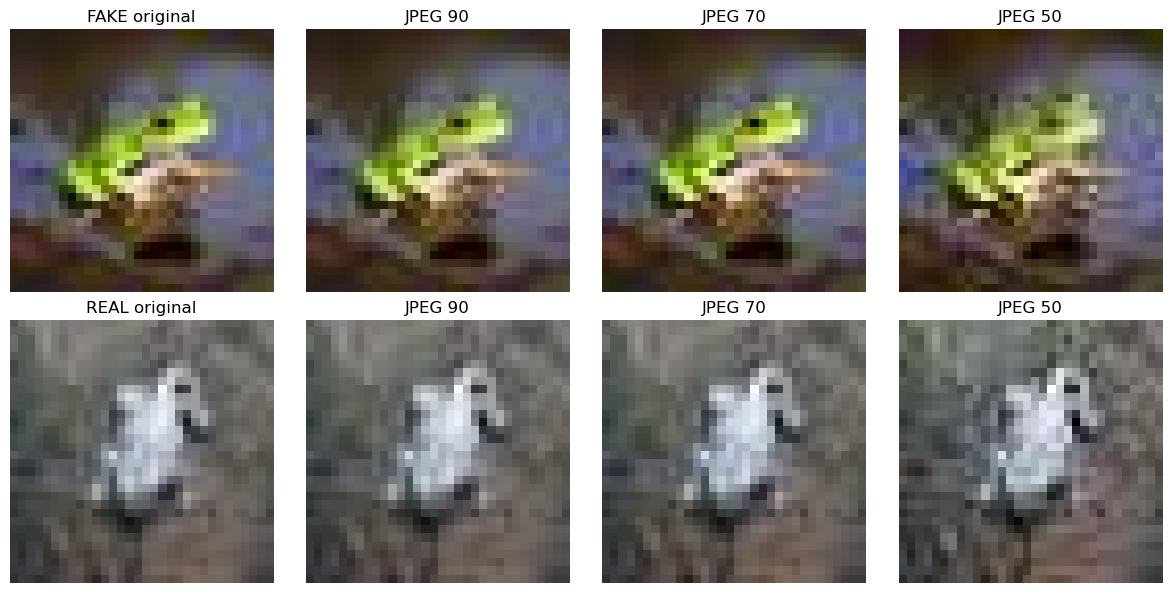

jpeg_compress OK | shapes: (32, 32, 3)


In [34]:
# Compressão JPEG
# Decisão: comprimir em memória (imencode/imdecode) — sem gravar arquivo temporário
# Decisão: qualidades 90 / 70 / 50, alinhadas ao artigo
# Saída: RGB uint8, mesmo formato usado pelos extratores

def jpeg_compress(imagem, qualidade=70):
    """Comprime a imagem em JPEG (em memória) e devolve RGB uint8."""
    bgr = cv2.cvtColor(imagem, cv2.COLOR_RGB2BGR)
    ok, buffer = cv2.imencode(
        ".jpg", bgr, [int(cv2.IMWRITE_JPEG_QUALITY), int(qualidade)]
    )
    if not ok:
        raise RuntimeError("Falha ao comprimir JPEG.")
    decodificada = cv2.imdecode(buffer, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decodificada, cv2.COLOR_BGR2RGB)


def _pegar_exemplo_por_classe(caminhos, rotulos, classe):
    for caminho, rotulo in zip(caminhos, rotulos):
        if rotulo == classe:
            return caminho
    raise ValueError(f"Nenhuma imagem da classe {classe} encontrada.")


# Teste visual: 1 FAKE e 1 REAL, qualidades 90 / 70 / 50
caminho_fake = _pegar_exemplo_por_classe(train_caminhos, train_rotulos, 0)
caminho_real = _pegar_exemplo_por_classe(train_caminhos, train_rotulos, 1)
img_fake = carregar_imagem(caminho_fake)
img_real = carregar_imagem(caminho_real)

fig, eixos = plt.subplots(2, 4, figsize=(12, 6))
qualidades = [90, 70, 50]

for linha, (titulo, img) in enumerate([("FAKE", img_fake), ("REAL", img_real)]):
    eixos[linha, 0].imshow(img)
    eixos[linha, 0].set_title(f"{titulo} original")
    eixos[linha, 0].axis("off")
    for col, q in enumerate(qualidades, start=1):
        eixos[linha, col].imshow(jpeg_compress(img, q))
        eixos[linha, col].set_title(f"JPEG {q}")
        eixos[linha, col].axis("off")

plt.tight_layout()
plt.show()
print("jpeg_compress OK | shapes:", jpeg_compress(img_fake, 70).shape)

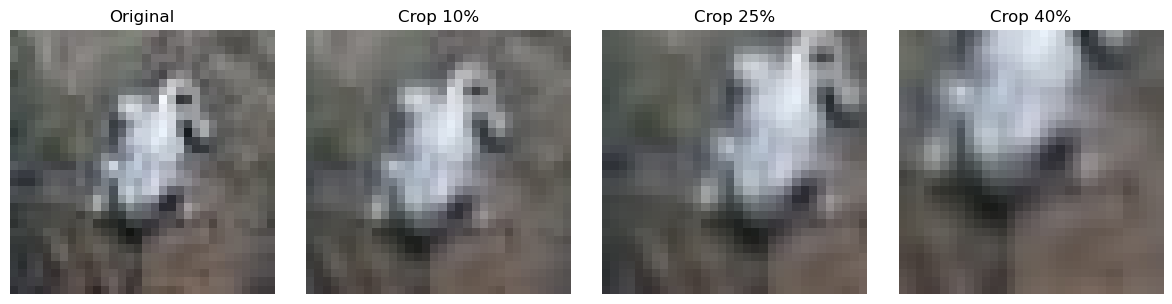

crop_aleatorio OK | shape: (32, 32, 3)


In [35]:
# Crop aleatório
# Decisão: crop aleatório (não só centro) para simular recortes reais de rede social
# Decisão: seed controlada para reprodutibilidade nos testes
# Decisão: após o crop, resize de volta a 32x32 — features/HOG exigem tamanho fixo

def crop_aleatorio(imagem, percentual=0.25, seed=None):
    """Remove `percentual` das bordas via crop aleatório e volta ao tamanho original.

    percentual=0.25 → mantém 75% da área (corta ~25%).
    """
    if not 0 < percentual < 1:
        raise ValueError("percentual deve estar entre 0 e 1 (ex.: 0.10, 0.25, 0.40).")

    h, w = imagem.shape[:2]
    novo_h = max(1, int(h * (1 - percentual)))
    novo_w = max(1, int(w * (1 - percentual)))

    rng = np.random.default_rng(seed)
    y0 = int(rng.integers(0, h - novo_h + 1))
    x0 = int(rng.integers(0, w - novo_w + 1))

    recorte = imagem[y0 : y0 + novo_h, x0 : x0 + novo_w]
    return cv2.resize(recorte, (w, h), interpolation=cv2.INTER_LINEAR)


# Teste visual (seed fixa para reprodutibilidade na demo)
img_demo = carregar_imagem(caminho_real)
percentuais = [0.10, 0.25, 0.40]

fig, eixos = plt.subplots(1, 4, figsize=(12, 3))
eixos[0].imshow(img_demo)
eixos[0].set_title("Original")
eixos[0].axis("off")

for i, p in enumerate(percentuais, start=1):
    eixos[i].imshow(crop_aleatorio(img_demo, p, seed=SEED + i))
    eixos[i].set_title(f"Crop {int(p * 100)}%")
    eixos[i].axis("off")

plt.tight_layout()
plt.show()
print("crop_aleatorio OK | shape:", crop_aleatorio(img_demo, 0.25, seed=SEED).shape)

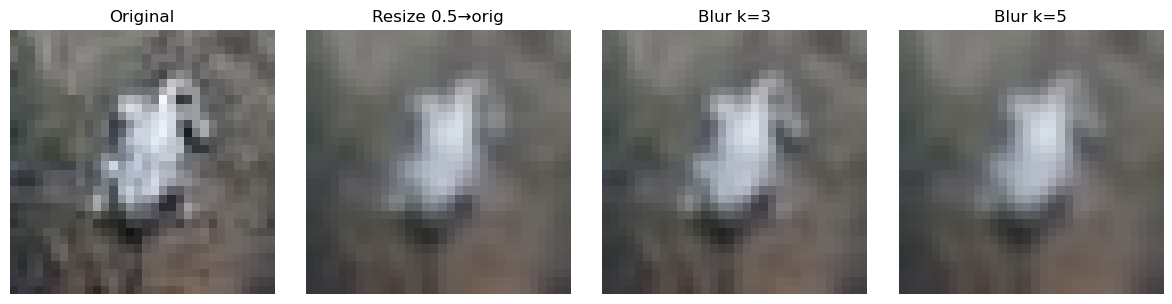

resize/blur OK | shapes: (32, 32, 3) (32, 32, 3)


In [36]:
# Resize e blur
# Decisão resize: reduzir e voltar ao original — imita perda de detalhe ao reenviar foto
# Decisão blur: GaussianBlur com ksize ímpar (OpenCV exige isso)
# Ambos mantêm shape 32x32x3

def resize_down_up(imagem, escala=0.5):
    """Reduz a imagem pela `escala` e reconstrói no tamanho original."""
    if not 0 < escala < 1:
        raise ValueError("escala deve estar entre 0 e 1 (ex.: 0.5).")

    h, w = imagem.shape[:2]
    novo_w = max(1, int(w * escala))
    novo_h = max(1, int(h * escala))

    reduzida = cv2.resize(imagem, (novo_w, novo_h), interpolation=cv2.INTER_AREA)
    return cv2.resize(reduzida, (w, h), interpolation=cv2.INTER_LINEAR)


def blur(imagem, ksize=3):
    """Aplica desfoque gaussiano. ksize deve ser ímpar."""
    k = int(ksize)
    if k % 2 == 0:
        k += 1
    return cv2.GaussianBlur(imagem, (k, k), 0)


fig, eixos = plt.subplots(1, 4, figsize=(12, 3))
eixos[0].imshow(img_demo)
eixos[0].set_title("Original")
eixos[0].axis("off")

eixos[1].imshow(resize_down_up(img_demo, 0.5))
eixos[1].set_title("Resize 0.5→orig")
eixos[1].axis("off")

eixos[2].imshow(blur(img_demo, 3))
eixos[2].set_title("Blur k=3")
eixos[2].axis("off")

eixos[3].imshow(blur(img_demo, 5))
eixos[3].set_title("Blur k=5")
eixos[3].axis("off")

plt.tight_layout()
plt.show()
print(
    "resize/blur OK | shapes:",
    resize_down_up(img_demo, 0.5).shape,
    blur(img_demo, 3).shape,
)

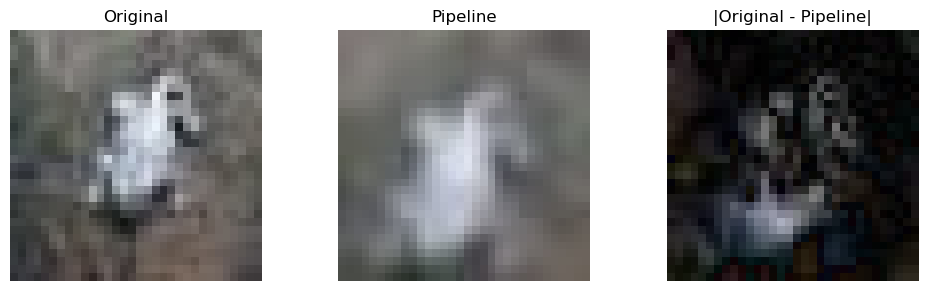

Transformações disponíveis:
  - jpeg_90      shape=(32, 32, 3) dtype=uint8
  - jpeg_70      shape=(32, 32, 3) dtype=uint8
  - jpeg_50      shape=(32, 32, 3) dtype=uint8
  - crop_10      shape=(32, 32, 3) dtype=uint8
  - crop_25      shape=(32, 32, 3) dtype=uint8
  - crop_40      shape=(32, 32, 3) dtype=uint8
  - resize_0.5   shape=(32, 32, 3) dtype=uint8
  - blur_3       shape=(32, 32, 3) dtype=uint8
  - pipeline     shape=(32, 32, 3) dtype=uint8


In [37]:
# Pipeline combinado + catálogo TRANSFORMACOES
# Decisão do pipeline: crop 25% → resize 0.5 → JPEG 70 (caminho típico de compartilhamento)
# Decisão: um dicionário nome→função centraliza o que o item 7 vai avaliar

def pipeline_compartilhamento(imagem, seed=SEED):
    """Simula circulação típica: crop → resize → JPEG."""
    img = crop_aleatorio(imagem, percentual=0.25, seed=seed)
    img = resize_down_up(img, escala=0.5)
    img = jpeg_compress(img, qualidade=70)
    return img


# Catálogo usado no item 7 (avaliação sob transformações)
TRANSFORMACOES = {
    "jpeg_90": lambda img: jpeg_compress(img, 90),
    "jpeg_70": lambda img: jpeg_compress(img, 70),
    "jpeg_50": lambda img: jpeg_compress(img, 50),
    "crop_10": lambda img: crop_aleatorio(img, 0.10, seed=SEED),
    "crop_25": lambda img: crop_aleatorio(img, 0.25, seed=SEED),
    "crop_40": lambda img: crop_aleatorio(img, 0.40, seed=SEED),
    "resize_0.5": lambda img: resize_down_up(img, 0.5),
    "blur_3": lambda img: blur(img, 3),
    "pipeline": lambda img: pipeline_compartilhamento(img, seed=SEED),
}

# Teste visual do pipeline + lista das transformações
fig, eixos = plt.subplots(1, 3, figsize=(10, 3))
eixos[0].imshow(img_demo)
eixos[0].set_title("Original")
eixos[0].axis("off")

eixos[1].imshow(pipeline_compartilhamento(img_demo))
eixos[1].set_title("Pipeline")
eixos[1].axis("off")

# Diferença absoluta (só para visualizar o impacto)
diff = cv2.absdiff(img_demo, pipeline_compartilhamento(img_demo))
eixos[2].imshow(diff)
eixos[2].set_title("|Original - Pipeline|")
eixos[2].axis("off")

plt.tight_layout()
plt.show()

print("Transformações disponíveis:")
for nome in TRANSFORMACOES:
    out = TRANSFORMACOES[nome](img_demo)
    print(f"  - {nome:12s} shape={out.shape} dtype={out.dtype}")

## 7. Avaliação sob transformações

Mesmo SVM do baseline; só o **teste** muda (imagens transformadas).

**Decisões desta seção:**
- Não retreinar o SVM — medimos robustez do modelo treinado em imagens intactas.
- Usar o **mesmo subconjunto de teste** do baseline (`test_caminhos_usados`), para comparar queda de forma justa.
- Cachear features transformadas em `local/`, evitando recalcular a cada execução.

In [38]:
# Avaliação de robustez sob transformações
# Decisão: o classificador permanece fixo (baseline); só o TESTE é alterado
# Decisão: mesmo subconjunto do baseline (test_caminhos_usados)
# Decisão: aplicar CADA transformação UMA vez e extrair FFT/HOG/LBP em seguida
#          (antes reaplicava 3x — lento demais para execução longa)
# Decisão: cache .npz por (feature, transformação, n) — retoma se interromper

def extrair_features_de_imagens(imagens, tipo_feature):
    """Extrai features a partir de imagens já carregadas (arrays RGB)."""
    extratores = {
        "fft": extrair_features_fft,
        "hog": extrair_features_hog,
        "lbp": extrair_features_lbp,
    }
    if tipo_feature not in extratores:
        raise ValueError(f"Feature inválida: {tipo_feature}")
    funcao = extratores[tipo_feature]
    vetores = [
        funcao(img)
        for img in tqdm(imagens, desc=f"Features {tipo_feature}", leave=False)
    ]
    return np.array(vetores)


def caminho_cache_transf(pasta_saida, tipo_feature, nome_transformacao, n):
    return Path(pasta_saida) / (
        f"features_{tipo_feature}_test_{nome_transformacao}_n{n}.npz"
    )


def obter_features_por_transformacao(
    caminhos,
    rotulos,
    nome_transformacao,
    funcao_transformacao,
    tipos,
    pasta_saida="./local",
    forcar_recalculo=False,
):
    """Retorna dict {tipo: X} e y. Aplica a transformação só se faltar algum cache."""
    diretorio = Path(pasta_saida)
    diretorio.mkdir(parents=True, exist_ok=True)
    n = len(caminhos)
    y = np.array(rotulos)

    caches = {
        tipo: caminho_cache_transf(pasta_saida, tipo, nome_transformacao, n)
        for tipo in tipos
    }
    Xs = {}
    faltando = []

    for tipo, caminho in caches.items():
        if caminho.exists() and not forcar_recalculo:
            dados = np.load(caminho)
            Xs[tipo] = dados["X"]
            print(f"  Cache: {caminho.name} | X={Xs[tipo].shape}")
        else:
            faltando.append(tipo)

    if faltando:
        imagens_transf = []
        for caminho_img in tqdm(
            caminhos, desc=f"Aplicando {nome_transformacao}", leave=False
        ):
            imagens_transf.append(funcao_transformacao(carregar_imagem(caminho_img)))

        for tipo in faltando:
            X = extrair_features_de_imagens(imagens_transf, tipo)
            np.savez_compressed(caches[tipo], X=X, y=y)
            Xs[tipo] = X
            print(f"  Salvo: {caches[tipo].name} | X={X.shape}")

    return Xs, y


# Recupera modelos/scalers se o kernel reiniciou no meio da noite
if "baseline_results" not in globals() or not baseline_results:
    baseline_results = {}
    for tipo in tipos_features:
        modelo_path = MODELS_DIR / f"svm_{tipo}.pkl"
        if not modelo_path.exists():
            raise FileNotFoundError(
                f"Modelo não encontrado: {modelo_path}. Rode o item 5 antes."
            )
        modelo = joblib.load(modelo_path)
        if "features" in globals() and tipo in features:
            y_pred = modelo.predict(features[tipo]["X_test"])
            acc = accuracy_score(features[tipo]["y_test"], y_pred)
        else:
            acc = float("nan")
        baseline_results[tipo] = {"modelo": modelo, "acuracia": acc}

if "scalers" not in globals() or not scalers:
    scalers = {}
    for tipo in tipos_features:
        scaler_path = MODELS_DIR / f"scaler_{tipo}.pkl"
        if not scaler_path.exists():
            raise FileNotFoundError(
                f"Scaler não encontrado: {scaler_path}. Rode o item 5 antes."
            )
        scalers[tipo] = joblib.load(scaler_path)

# Checagens rápidas antes do loop longo
assert "TRANSFORMACOES" in globals() and TRANSFORMACOES, "Rode o item 6 antes."
assert "test_caminhos_usados" in globals() and len(test_caminhos_usados) > 0
assert set(tipos_features).issubset(baseline_results.keys())
assert set(tipos_features).issubset(scalers.keys())
if "fusion" not in baseline_results:
    fusion_path = MODELS_DIR / "svm_fusion.pkl"
    if fusion_path.exists():
        modelo_f = joblib.load(fusion_path)
        # Recalcula baseline da fusão se features originais estão em memória
        if "features" in globals() and "fusion" in features:
            y_pred_f = modelo_f.predict(features["fusion"]["X_test"])
            acc_f = accuracy_score(features["fusion"]["y_test"], y_pred_f)
        else:
            acc_f = float("nan")
        baseline_results["fusion"] = {"modelo": modelo_f, "acuracia": acc_f}
    else:
        raise FileNotFoundError("Fusão não treinada. Rode o item 5.")

print(
    f"Pronto para avaliar {len(TRANSFORMACOES)} transformações "
    f"× {len(tipos_features)} features (+ FUSION) em {len(test_caminhos_usados)} imagens."
)

resultados_robustez = []

for nome_transf, funcao_transf in TRANSFORMACOES.items():
    print(f"\n=== Transformação: {nome_transf} ===")
    Xs_transf, y_transf = obter_features_por_transformacao(
        caminhos=test_caminhos_usados,
        rotulos=test_rotulos_usados,
        nome_transformacao=nome_transf,
        funcao_transformacao=funcao_transf,
        tipos=tipos_features,
        pasta_saida="./local",
    )

    # Features isoladas
    X_scaled_por_tipo = {}
    for tipo in tipos_features:
        X_scaled = scalers[tipo].transform(Xs_transf[tipo])
        X_scaled_por_tipo[tipo] = X_scaled
        y_pred = baseline_results[tipo]["modelo"].predict(X_scaled)
        acc = accuracy_score(y_transf, y_pred)
        baseline_acc = baseline_results[tipo]["acuracia"]
        queda = baseline_acc - acc
        resultados_robustez.append(
            {
                "transformacao": nome_transf,
                "feature": tipo.upper(),
                "acuracia": acc,
                "baseline": baseline_acc,
                "queda": queda,
            }
        )
        print(
            f"  {tipo.upper():3s} | acc={acc:.4f} | baseline={baseline_acc:.4f} | queda={queda:+.4f}"
        )

    # Fusão = concat das features já escaladas (mesma ordem do treino)
    X_fusion = np.hstack([X_scaled_por_tipo[t] for t in tipos_features])
    y_pred_f = baseline_results["fusion"]["modelo"].predict(X_fusion)
    acc_f = accuracy_score(y_transf, y_pred_f)
    base_f = baseline_results["fusion"]["acuracia"]
    queda_f = base_f - acc_f
    resultados_robustez.append(
        {
            "transformacao": nome_transf,
            "feature": "FUSION",
            "acuracia": acc_f,
            "baseline": base_f,
            "queda": queda_f,
        }
    )
    print(
        f"  FUSION | acc={acc_f:.4f} | baseline={base_f:.4f} | queda={queda_f:+.4f}"
    )

print(f"\nTotal de avaliações: {len(resultados_robustez)}")

Pronto para avaliar 9 transformações × 3 features em 600 imagens de teste.

=== Transformação: jpeg_90 ===
  Cache: features_fft_test_jpeg_90_n600.npz | X=(600, 64)
  Cache: features_hog_test_jpeg_90_n600.npz | X=(600, 288)
  Cache: features_lbp_test_jpeg_90_n600.npz | X=(600, 10)
  FFT | acc=0.7467 | baseline=0.7600 | queda=+0.0133
  HOG | acc=0.6867 | baseline=0.6950 | queda=+0.0083
  LBP | acc=0.6917 | baseline=0.7017 | queda=+0.0100

=== Transformação: jpeg_70 ===
  Cache: features_fft_test_jpeg_70_n600.npz | X=(600, 64)
  Cache: features_hog_test_jpeg_70_n600.npz | X=(600, 288)
  Cache: features_lbp_test_jpeg_70_n600.npz | X=(600, 10)
  FFT | acc=0.7550 | baseline=0.7600 | queda=+0.0050
  HOG | acc=0.6883 | baseline=0.6950 | queda=+0.0067
  LBP | acc=0.6950 | baseline=0.7017 | queda=+0.0067

=== Transformação: jpeg_50 ===
  Cache: features_fft_test_jpeg_50_n600.npz | X=(600, 64)
  Cache: features_hog_test_jpeg_50_n600.npz | X=(600, 288)
  Cache: features_lbp_test_jpeg_50_n600.npz 

In [39]:
# Consolida resultados em tabela e salva CSV
# Decisão: ordenar pela maior queda — facilita ver o que mais prejudica o detector
# Colunas: transformacao | feature | acuracia | baseline | queda

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df_robustez = pd.DataFrame(resultados_robustez)
df_robustez = df_robustez.sort_values("queda", ascending=False).reset_index(drop=True)

# Arredonda para leitura no relatório/poster
df_exibir = df_robustez.copy()
for col in ["acuracia", "baseline", "queda"]:
    df_exibir[col] = df_exibir[col].map(lambda x: f"{x:.4f}")

caminho_csv = RESULTS_DIR / "metrics.csv"
df_robustez.to_csv(caminho_csv, index=False)

print("Tabela de robustez (maior queda primeiro):")
print(df_exibir.to_string(index=False))
print(f"\nCSV salvo em: {caminho_csv}")

# Atalho: pior caso por feature (inclui FUSION)
print("\nMaior queda por feature:")
for feat in [t.upper() for t in tipos_features] + ["FUSION"]:
    subset = df_robustez[df_robustez["feature"] == feat].iloc[0]
    print(
        f"  {feat:6s} → {subset['transformacao']} "
        f"(queda={subset['queda']:+.4f}, acc={subset['acuracia']:.4f})"
    )
print(
    f"\nBaseline FUSION (sem transformação): "
    f"{baseline_results['fusion']['acuracia']:.4f}"
)

Tabela de robustez (maior queda primeiro):
transformacao feature acuracia baseline  queda
     pipeline     FFT   0.4817   0.7600 0.2783
      crop_25     FFT   0.4933   0.7600 0.2667
   resize_0.5     FFT   0.4933   0.7600 0.2667
      crop_40     FFT   0.4967   0.7600 0.2633
       blur_3     FFT   0.5033   0.7600 0.2567
      crop_10     FFT   0.5100   0.7600 0.2500
      crop_40     LBP   0.5033   0.7017 0.1983
     pipeline     LBP   0.5067   0.7017 0.1950
      jpeg_50     FFT   0.5883   0.7600 0.1717
   resize_0.5     LBP   0.5350   0.7017 0.1667
      crop_25     LBP   0.5717   0.7017 0.1300
       blur_3     LBP   0.5817   0.7017 0.1200
      crop_25     HOG   0.5850   0.6950 0.1100
     pipeline     HOG   0.5867   0.6950 0.1083
      crop_40     HOG   0.5933   0.6950 0.1017
      crop_10     LBP   0.6233   0.7017 0.0783
   resize_0.5     HOG   0.6450   0.6950 0.0500
      crop_10     HOG   0.6533   0.6950 0.0417
       blur_3     HOG   0.6650   0.6950 0.0300
      jpeg_50    

## 8. Gráficos e análise

Material para poster, slides e relatório.

**Decisões desta seção:**
- Barras agrupadas por transformação (série = feature) + linha/marcador do baseline.
- Heatmap da **queda** (não só acurácia), para destacar degradação.
- Figuras salvas em `results/` para reutilizar nas entregas.

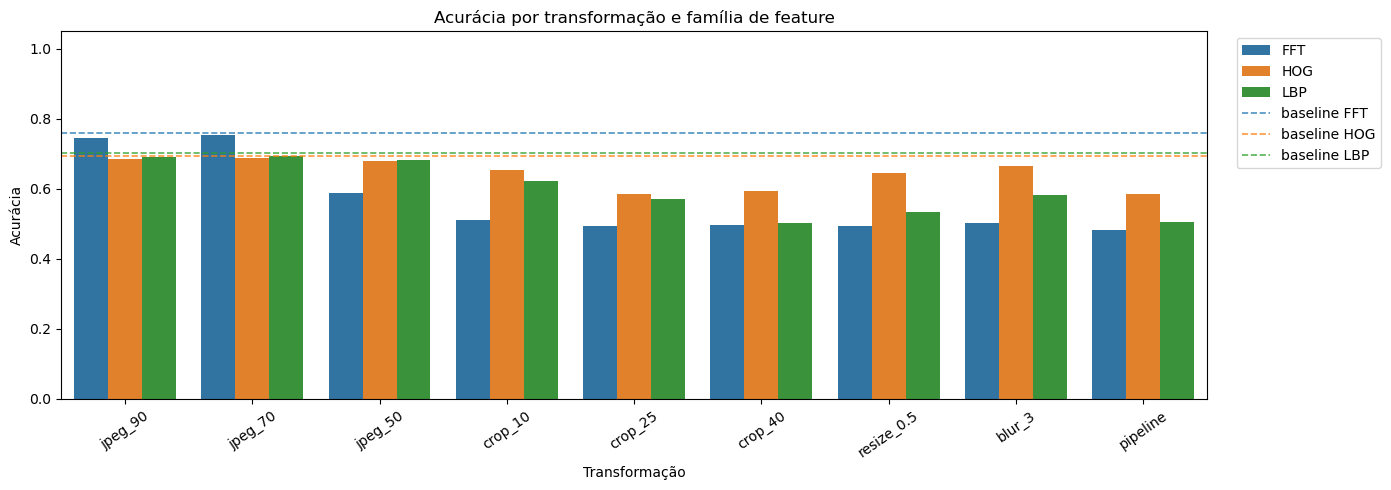

Figura salva em: /home/igor/Documentos/UFSC/Trabalhos/VisaoComp/DeteccaoImagensSinteticas/Cod/results/acuracia_por_transformacao.png


In [40]:
# Gráfico de barras: acurácia por transformação × feature
# Decisão: incluir marcadores do baseline por feature para leitura rápida da queda
# Saída: results/acuracia_por_transformacao.png

# Ordem fixa das transformações (igual ao dicionário TRANSFORMACOES)
ordem_transf = list(TRANSFORMACOES.keys())
ordem_features = [t.upper() for t in tipos_features] + ["FUSION"]

df_plot = df_robustez.copy()
df_plot["transformacao"] = pd.Categorical(
    df_plot["transformacao"], categories=ordem_transf, ordered=True
)
df_plot["feature"] = pd.Categorical(
    df_plot["feature"], categories=ordem_features, ordered=True
)
df_plot = df_plot.sort_values(["transformacao", "feature"])

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(
    data=df_plot,
    x="transformacao",
    y="acuracia",
    hue="feature",
    ax=ax,
)

# Linha horizontal por baseline de cada feature (média visual de referência)
series_baseline = list(tipos_features) + ["fusion"]
cores = sns.color_palette(n_colors=len(series_baseline))
for i, tipo in enumerate(series_baseline):
    ax.axhline(
        baseline_results[tipo]["acuracia"],
        color=cores[i],
        linestyle="--",
        linewidth=1.2,
        alpha=0.8,
        label=f"baseline {tipo.upper()}",
    )

ax.set_title("Acurácia por transformação e família de feature")
ax.set_xlabel("Transformação")
ax.set_ylabel("Acurácia")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

caminho_fig = RESULTS_DIR / "acuracia_por_transformacao.png"
fig.savefig(caminho_fig, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em: {caminho_fig}")

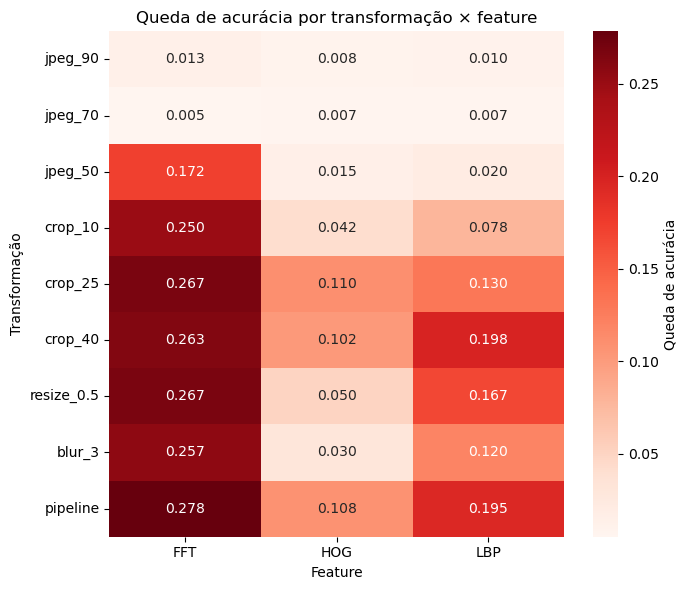

Figura salva em: /home/igor/Documentos/UFSC/Trabalhos/VisaoComp/DeteccaoImagensSinteticas/Cod/results/heatmap_queda.png

--- Síntese para o relatório ---
Maior queda pontual: FFT sob pipeline (queda=+0.2783).
Queda média por feature:
  FFT: +0.1969
  LBP: +0.1028
  HOG: +0.0524

Interpretação sugerida (ajustar com os números obtidos):
- FFT (frequência): tende a sofrer com JPEG, que altera o espectro.
- HOG (espaço/gradientes): sensível a blur e resize, que suavizam bordas.
- LBP (textura): sensível a compressão/blur que mudam padrões locais.
Use o heatmap acima para confirmar qual domínio degradou mais neste experimento.


In [41]:
# Heatmap da queda de acurácia (baseline - acurácia transformada)
# Decisão: valores positivos = piora; facilita comparar domínios (freq/espaço/textura)
# Saída: results/heatmap_queda.png

pivot_queda = df_robustez.pivot(
    index="transformacao", columns="feature", values="queda"
).reindex(index=ordem_transf, columns=ordem_features)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    pivot_queda,
    annot=True,
    fmt=".3f",
    cmap="Reds",
    ax=ax,
    cbar_kws={"label": "Queda de acurácia"},
)
ax.set_title("Queda de acurácia por transformação × feature")
ax.set_xlabel("Feature")
ax.set_ylabel("Transformação")
plt.tight_layout()

caminho_heat = RESULTS_DIR / "heatmap_queda.png"
fig.savefig(caminho_heat, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em: {caminho_heat}")

# Síntese automática para apoiar discussão no relatório
pior_linha = df_robustez.iloc[0]
media_por_feature = df_robustez.groupby("feature")["queda"].mean().sort_values(ascending=False)

print("\n--- Síntese para o relatório ---")
print(
    f"Maior queda pontual: {pior_linha['feature']} sob {pior_linha['transformacao']} "
    f"(queda={pior_linha['queda']:+.4f})."
)
print("Queda média por feature:")
for feat, valor in media_por_feature.items():
    print(f"  {feat}: {valor:+.4f}")

print(
    "\nInterpretação sugerida (ajustar com os números obtidos):\n"
    "- FFT (frequência): tende a sofrer com JPEG, que altera o espectro.\n"
    "- HOG (espaço/gradientes): sensível a blur e resize, que suavizam bordas.\n"
    "- LBP (textura): sensível a compressão/blur que mudam padrões locais.\n"
    "Use o heatmap acima para confirmar qual domínio degradou mais neste experimento."
)